In [29]:
# 0. Programming Environment Setup

# Numerical computing and data handling
import numpy as np
import pandas as pd
from pathlib import Path

#modelling`
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.metrics import max_error, mean_absolute_error, mean_absolute_percentage_error, mean_squared_error
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge
from sklearn.kernel_ridge import KernelRidge
from sklearn.linear_model import Lasso
from math import degrees
from sklearn.preprocessing import PolynomialFeatures
from sklearn.ensemble import VotingRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from xgboost import XGBRegressor
from sklearn.neighbors import KNeighborsRegressor


#dummy modelling
from sklearn.dummy import DummyRegressor
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    max_error,
    mean_absolute_percentage_error,
    root_mean_squared_error
)


# plotting
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
%matplotlib inline


In [30]:
#import dataset
DATA_DIR = Path.cwd().parent / "EDA"
INPUT_FILE = DATA_DIR / "cleaned_data.csv"

eda_df = pd.read_csv(INPUT_FILE, keep_default_na=False, na_values=[""])
includeNaN_df = eda_df.copy()
includeNaN_df = includeNaN_df.drop(columns=['Z', 'N'])
includeNaN_df.head() #Keep NaN
RANDOM_SEED = 1
np.random.seed(RANDOM_SEED)

In [31]:
#split datset into test and train
df_train_includeNaN, df_test = train_test_split(
    includeNaN_df,
    test_size=0.2,  # 20% for testing
    random_state=RANDOM_SEED  # Ensure reproducibility
)
target_includeNaN = df_train_includeNaN['log_half_life'].name

features = [
    "A",
    "N/Z",
    "Q_beta_keV",
    "Q_alpha_keV",
    "S_n_keV",
    "S_p_keV"
]

#create training sets for dropped NaNs
df_train_dropNaN = df_train_includeNaN.dropna()
target_dropNaN = df_train_dropNaN['log_half_life'].name

#imputed NaNs
# don't have to create a separate training set since these will be imputed from includeNaN_df using Pipelines



#TEST SET
df_test = df_test.dropna() #complete test set, drops all NaNs, we will use this test set for all models

print(df_train_dropNaN.shape)


(1306, 8)


In [32]:
#Regression metrics function
def get_regression_metrics(model, X, y_true):

    y_predicted = model.predict(X)

    mae = mean_absolute_error(y_true, y_predicted)
    mse = mean_squared_error(y_true, y_predicted)
    maximum_error = max_error(y_true, y_predicted)
    rmse = root_mean_squared_error(y_true, y_predicted)

    metrics_dict = {
        'mae': mae,
        'mse': mse,
        'max_error': maximum_error,
        'rmse': rmse,
        'r^2': r2_score(y_true, y_predicted)
    }

    return metrics_dict

In [33]:
#Included NaN best model: XGBoost
xgb_includeNaN = Pipeline([
    ('scaling', StandardScaler()),
    ('xgb', XGBRegressor(
        n_estimators=1200,
        learning_rate=0.1,
        max_depth=7,
        random_state=42
    ))
])

xgb_includeNaN.fit(df_train_includeNaN[features], df_train_includeNaN[target_includeNaN])

xgb_includeNaN_results_train = get_regression_metrics(
    xgb_includeNaN, df_train_includeNaN[features], df_train_includeNaN[target_includeNaN]
)

xgb_includeNaN_results_test = get_regression_metrics(
    xgb_includeNaN, df_test[features], df_test[target_includeNaN]
)

# Create dataframe
xgb_includeNaN_results_df = pd.DataFrame(
    [xgb_includeNaN_results_train, xgb_includeNaN_results_test],
    index=['Train', 'Test']
)

# Round to 4 decimal places
xgb_includeNaN_results_df = xgb_includeNaN_results_df.round(4)

# Add model name
xgb_includeNaN_results_df.insert(0, 'Model', 'XGboost Regression')

# Display dataframe
display(xgb_includeNaN_results_df)

,Model,mae,mse,max_error,rmse,r^2
Train,XGboost Regression,0.0038,0.0002,0.3745,0.0130,1.0000
Test,XGboost Regression,0.8082,1.5151,5.9743,1.2309,0.8547


In [34]:
#need to build Ensemble Model
#imputed 
xgb_imputeNaN = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaling', StandardScaler()),
    ('xgb', XGBRegressor(
        n_estimators=300,
        learning_rate=0.1,
        max_depth=5,
        random_state=42
    ))
])

xgb_imputeNaN.fit(df_train_includeNaN[features], df_train_includeNaN[target_includeNaN])

xgb_imputeNaN_results_train = get_regression_metrics(
    xgb_imputeNaN, df_train_includeNaN[features], df_train_includeNaN[target_includeNaN]
)

xgb_imputeNaN_results_test = get_regression_metrics(
    xgb_imputeNaN, df_test[features], df_test[target_includeNaN]
)

# Create dataframe
xgb_imputeNaN_results_df = pd.DataFrame(
    [xgb_imputeNaN_results_train, xgb_imputeNaN_results_test],
    index=['Train', 'Test']
)

# Round to 4 decimal places
xgb_imputeNaN_results_df = xgb_imputeNaN_results_df.round(4)

# Add model name
xgb_imputeNaN_results_df.insert(0, 'Model', 'XGBoost Regression')

# Display dataframe
display(xgb_imputeNaN_results_df)


,Model,mae,mse,max_error,rmse,r^2
Train,XGBoost Regression,0.3346,0.2305,3.3457,0.4801,0.9777
Test,XGBoost Regression,0.8401,1.5731,5.3871,1.2542,0.8491


In [35]:
rf_imputeNaN = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaling', StandardScaler()),
    ('rf', RandomForestRegressor(
        n_estimators=300,
        max_depth=20,
        min_samples_split=2,
        min_samples_leaf=1,
        random_state=42
    ))
])

rf_imputeNaN.fit(df_train_includeNaN[features], df_train_includeNaN[target_includeNaN])

rf_imputeNaN_results_train = get_regression_metrics(
    rf_imputeNaN, df_train_includeNaN[features], df_train_includeNaN[target_includeNaN]
)

rf_imputeNaN_results_test = get_regression_metrics(
    rf_imputeNaN, df_test[features], df_test[target_includeNaN]
)

# Create dataframe
rf_imputeNaN_results_df = pd.DataFrame(
    [rf_imputeNaN_results_train, rf_imputeNaN_results_test],
    index=['Train', 'Test']
)

# Round to 4 decimal places
rf_imputeNaN_results_df = rf_imputeNaN_results_df.round(4)

# Add model name
rf_imputeNaN_results_df.insert(0, 'Model', 'Random Forest')

# Display dataframe
display(rf_imputeNaN_results_df)


,Model,mae,mse,max_error,rmse,r^2
Train,Random Forest,0.3467,0.2998,5.1702,0.5475,0.9710
Test,Random Forest,0.8406,1.7211,7.5347,1.3119,0.8349


In [36]:
#KRR for imputed
krr_imputeNaN = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaling', StandardScaler()),
    ('krr', KernelRidge(
        alpha=0.1,
        kernel='rbf',
        gamma=1.0
    ))
])


krr_imputeNaN.fit(df_train_includeNaN[features], df_train_includeNaN[target_includeNaN])

krr_imputeNaN_results_train = get_regression_metrics(
    krr_imputeNaN, df_train_includeNaN[features], df_train_includeNaN[target_includeNaN]
)

krr_imputeNaN_results_test = get_regression_metrics(
    krr_imputeNaN, df_test[features], df_test[target_includeNaN]
)

# Create dataframe
krr_imputeNaN_results_df = pd.DataFrame(
    [krr_imputeNaN_results_train, krr_imputeNaN_results_test],
    index=['Train', 'Test']
)

# Round to 4 decimal places
krr_imputeNaN_results_df = krr_imputeNaN_results_df.round(4)

# Add model name
krr_imputeNaN_results_df.insert(0, 'Model', 'Kernel Ridge Regression')

# Display dataframe
display(krr_imputeNaN_results_df)

,Model,mae,mse,max_error,rmse,r^2
Train,Kernel Ridge Regression,0.6708,1.0812,8.2907,1.0398,0.8953
Test,Kernel Ridge Regression,0.8741,1.8428,6.2635,1.3575,0.8232


In [37]:
#Ensemble for imputed
#ensemble model
ensemble_model = VotingRegressor(
    estimators=[
        ('random forest', rf_imputeNaN),
        ('xgb', xgb_imputeNaN),
        ('krr', krr_imputeNaN),
    ]
)

ensemble_model.fit(
    df_train_includeNaN[features],
    df_train_includeNaN[target_includeNaN]
)
ensemble_model_results_train = get_regression_metrics(ensemble_model, df_train_includeNaN[features], df_train_includeNaN[target_includeNaN])
ensemble_model_results_test = get_regression_metrics(ensemble_model, df_test[features], df_test[target_includeNaN])

# Create dataframe
ensemble_model_results_df = pd.DataFrame(
    [ensemble_model_results_train, ensemble_model_results_test],
    index=['Train', 'Test']
)

# Round to 4 decimal places
ensemble_model_results_df = ensemble_model_results_df.round(4)

# Add model name
ensemble_model_results_df.insert(0, 'Model', 'Ensemble')

# Display dataframe
display(ensemble_model_results_df)

,Model,mae,mse,max_error,rmse,r^2
Train,Ensemble,0.4129,0.3921,3.6095,0.6262,0.9620
Test,Ensemble,0.7906,1.4951,5.4348,1.2227,0.8566


In [38]:
#KRR for dropped NaN
#KRR for imputed
krr_NaN = Pipeline([
    ('scaling', StandardScaler()),
    ('krr', KernelRidge(
        alpha=0.1,
        kernel='rbf',
        gamma=1.0
    ))
])


krr_NaN.fit(df_train_dropNaN[features], df_train_dropNaN[target_dropNaN])

krr_NaN_results_train = get_regression_metrics(
    krr_NaN, df_train_dropNaN[features], df_train_dropNaN[target_dropNaN]
)

krr_NaN_results_test = get_regression_metrics(
    krr_NaN, df_test[features], df_test[target_dropNaN]
)

# Create dataframe
krr_NaN_results_df = pd.DataFrame(
    [krr_NaN_results_train, krr_NaN_results_test],
    index=['Train', 'Test']
)

# Round to 4 decimal places
krr_NaN_results_df = krr_NaN_results_df.round(4)

# Add model name
krr_NaN_results_df.insert(0, 'Model', 'Kernel Ridge Regression (Dropped)')

# Display dataframe
display(krr_NaN_results_df)

,Model,mae,mse,max_error,rmse,r^2
Train,Kernel Ridge Regression (Dropped),0.7066,1.1611,7.7239,1.0776,0.8901
Test,Kernel Ridge Regression (Dropped),0.8947,1.8833,6.3175,1.3723,0.8194


In [43]:
# Create dataframe containing all test results
all_results_test_df = pd.DataFrame({
    'Drop NaN (KRR)': krr_NaN_results_test,
    'Include NaN (XBoost)': xgb_includeNaN_results_test,
    'Impute NaN (Ensemble)': ensemble_model_results_test,

})

# Transpose dataframe
all_results_test_df = all_results_test_df.T

# Add model categories
all_results_test_df.insert(0, 'Model Category', [
    'Kernel',
    'Ensemble',
    'Tree Based'])

# Add model names
all_results_test_df.insert(1, 'Model', all_results_test_df.index)

# Reset index
all_results_test_df = all_results_test_df.reset_index(drop=True)

# Round to 4 decimal places
all_results_test_df = all_results_test_df.round(4)


# Display test results
print("\nTEST SET MODEL PERFORMANCE")
display(all_results_test_df)


TEST SET MODEL PERFORMANCE


,Model Category,Model,mae,mse,max_error,rmse,r^2
0,Kernel,Drop NaN (KRR),0.8947,1.8833,6.3175,1.3723,0.8194
1,Ensemble,Include NaN (XBoost),0.8082,1.5151,5.9743,1.2309,0.8547
2,Tree Based,Impute NaN (Ensemble),0.7906,1.4951,5.4348,1.2227,0.8566


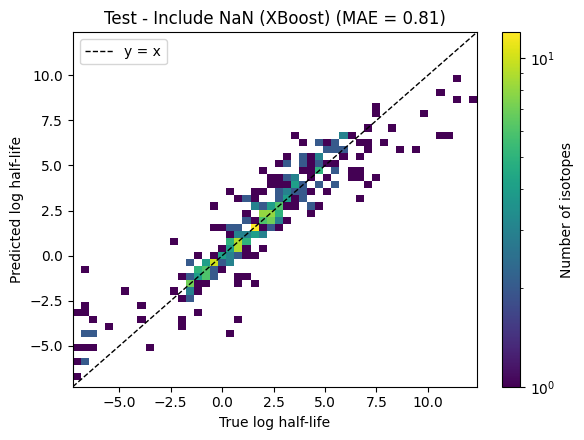

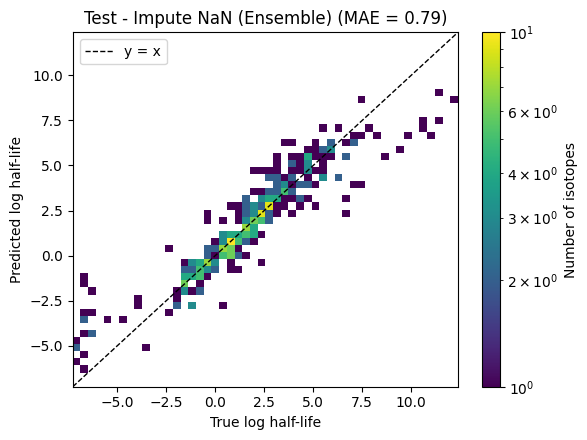

In [40]:
# Define models
models = {
    'Include NaN (XBoost)': xgb_includeNaN,
    'Impute NaN (Ensemble)': ensemble_model,
}

# Define parity plot function
def hist_density(y_true, y_pred, xlabel='True log half-life',
                 ylabel='Predicted log half-life', title=None, bins=50):

    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)

    lims = [
        min(y_true.min(), y_pred.min()),
        max(y_true.max(), y_pred.max())
    ]

    mae = np.mean(np.abs(y_true - y_pred))

    # Create individual figure
    fig, ax = plt.subplots(figsize=(6, 4.5))

    h = ax.hist2d(
        y_true, y_pred,
        bins=bins,
        range=[lims, lims],
        cmin=1,
        cmap='viridis',
        norm=LogNorm()
    )

    # Add colour bar
    fig.colorbar(h[3], ax=ax, label='Number of isotopes')

    # Add parity line
    ax.plot(lims, lims, 'k--', lw=1, label='y = x')

    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(
        f"{title} (MAE = {mae:.2f})" if title else f"MAE = {mae:.2f}"
    )

    ax.legend(loc='upper left')

    plt.tight_layout()
    plt.show()


# Generate individual parity plots for all models
for name, model in models.items():

    y_pred = model.predict(df_test[features])

    hist_density(
        df_test[target_includeNaN],
        y_pred,
        title=f'Test - {name}'
    )

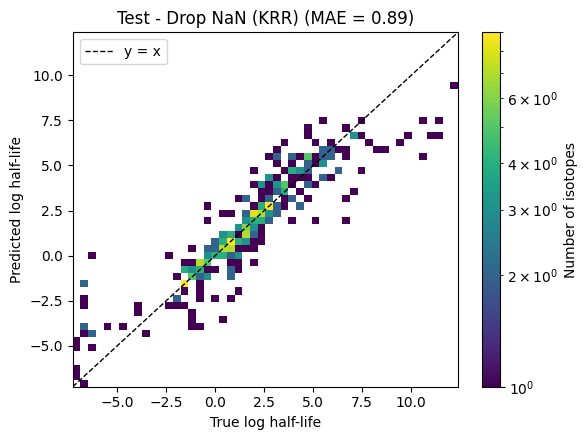

In [41]:
models = {
    'Drop NaN (KRR)': krr_NaN
}

# Define parity plot function
def hist_density(y_true, y_pred, xlabel='True log half-life',
                 ylabel='Predicted log half-life', title=None, bins=50):

    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)

    lims = [
        min(y_true.min(), y_pred.min()),
        max(y_true.max(), y_pred.max())
    ]

    mae = np.mean(np.abs(y_true - y_pred))

    # Create individual figure
    fig, ax = plt.subplots(figsize=(6, 4.5))

    h = ax.hist2d(
        y_true, y_pred,
        bins=bins,
        range=[lims, lims],
        cmin=1,
        cmap='viridis',
        norm=LogNorm()
    )

    # Add colour bar
    fig.colorbar(h[3], ax=ax, label='Number of isotopes')

    # Add parity line
    ax.plot(lims, lims, 'k--', lw=1, label='y = x')

    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(
        f"{title} (MAE = {mae:.2f})" if title else f"MAE = {mae:.2f}"
    )

    ax.legend(loc='upper left')

    plt.tight_layout()
    plt.show()


# Generate individual parity plots for all models
for name, model in models.items():

    y_pred = model.predict(df_test[features])

    hist_density(
        df_test[target_dropNaN],
        y_pred,
        title=f'Test - {name}'
    )